In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import functions as fns
import numpy as np
import matplotlib.cm as cm
import matplotlib.colors as mcolors

In [2]:
case = 'carma_SDPSul_CS_optics_test_cf30,50,70,90_bin1,10000nm'
ds = xr.open_dataset(f'/home/n02/n02/hqmp0145/CARMA/run/carma/{case}.nc', decode_times=False)

In [3]:
ds = ds.sortby("wave")

variable_label = {
    'PRSUL': 'Pure sulphate', 
                  # 'ALSUL_fixed_wet': 'Al-Sul wet - fixed core', 
                  'ALSUL_fixed_dry': 'Al-Sul dry - fixed core',
                  # 'ALSUL_coreshell_cf90_wet': 'Al-Sul wet - core/shell cf90', 
                  'ALSUL_coreshell_cf90_dry': 'Al-Sul dry - core/shell cf90',
                  # 'ALSUL_coreshell_cf70_wet': 'Al-Sul wet - core/shell cf70', 
                  'ALSUL_coreshell_cf70_dry': 'Al-Sul dry - core/shell cf70',
                  # 'ALSUL_coreshell_cf50_wet': 'Al-Sul wet - core/shell cf50', 
                  'ALSUL_coreshell_cf50_dry': 'Al-Sul dry - core/shell cf50',
                  # 'ALSUL_coreshell_cf30_wet': 'Al-Sul wet - core/shell cf30', 
                  'ALSUL_coreshell_cf30_dry': 'Al-Sul dry - core/shell cf30',
                  }

plot_dir = '/home/n02/n02/hqmp0145/CARMA/analysis/plots'

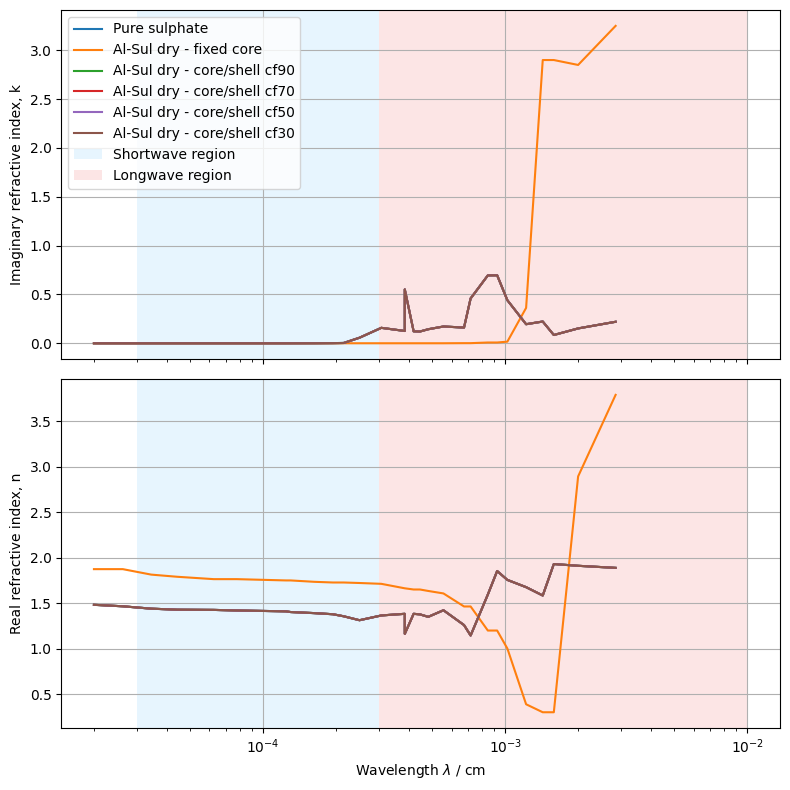

In [4]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 8))

for variable in variable_label.keys():
# Top: imaginary refractive index
    ds[f'{variable}_refidx_i'].plot(
        ax=ax[0],
        xscale='log',
        # alpha=0.6,
        # ls='--',
        label=variable_label[variable]
    )

    # Bottom: real refractive index
    ds[f'{variable}_refidx_r'].plot(
        ax=ax[1],
        xscale='log'
    )

# Wavelength axis / SW-LW regions
fns.wavelength_x(ax[1])
ax[0].set_xlabel('')
fns.add_SW_LW_plot_areas(ax[0])
fns.add_SW_LW_plot_areas(ax[1])

ax[0].legend()

ax[0].grid()
ax[1].grid()
ax[0].set_ylabel("Imaginary refractive index, k")
ax[1].set_ylabel("Real refractive index, n")

plt.tight_layout()


In [5]:
target_radii = [1e-7, 1e-6, 1e-5, 1e-4, 1e-3] # target radii for 1, 10, 100, 1000, 10,000nm particles 

def find_bin_index(ds, target_radius, variable):
    radii = ds[f"{variable}_r"]
    index = abs(np.log10(radii) - np.log10(target_radius)).argmin(dim="bin") 
    return int(index) + 1, float(radii.isel(bin=index))

radii_dict_dry = {}
for r in target_radii:
    idx, rad = find_bin_index(ds, r, "ALSUL_fixed_dry")
    radii_dict_dry[r] = idx
    print(f"target {r:.0e} cm -> bin {idx}, radius {rad:.3e} cm")

radii_dict_dry

target 1e-07 cm -> bin 1, radius 1.000e-07 cm
target 1e-06 cm -> bin 10, radius 1.000e-06 cm
target 1e-05 cm -> bin 19, radius 1.000e-05 cm
target 1e-04 cm -> bin 28, radius 1.000e-04 cm
target 1e-03 cm -> bin 37, radius 1.000e-03 cm


{1e-07: 1, 1e-06: 10, 1e-05: 19, 0.0001: 28, 0.001: 37}

In [6]:
def plot_optical_property(property_name, ylabel=None, yscale='linear', save=False):
    if len(target_radii) > 5:
        raise ValueError('This layout supports at most five target radii.')

    fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True, sharey=True)
    axes = axes.flatten()

    # Assign one color to each dry/wet variable pair.
    color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']
    variable_groups = {}
    for variable in variable_label:
        dry_variable = variable.replace('wet', 'dry')
        variable_groups.setdefault(dry_variable, []).append(variable)
    color_by_group = {
        group: color_cycle[index % len(color_cycle)]
        for index, group in enumerate(variable_groups)
    }

    for ax, target_radius in zip(axes, target_radii):
        for variable, label in variable_label.items():
            bin_number, _ = find_bin_index(ds, target_radius, variable)
            ds[f'{variable}_{property_name}'].isel(bin=bin_number - 1).plot(
                ax=ax,
                xscale='log',
                color=color_by_group[variable.replace('wet', 'dry')],
                linestyle='--' if 'wet' in variable else '-',
                label=label,
            )

        ax.set_title(f'Radius = {target_radius * 1e7:.0f} nm')
        ax.set_yscale(yscale)
        ax.grid()
        fns.add_SW_LW_plot_areas(ax)

    # Use the sixth subplot for the shared legend.
    legend_ax = axes[5]
    legend_ax.axis('off')
    handles, labels = axes[0].get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc='center')

    # Show y-labels only on the left edge and x-labels only on the bottom edge.
    for ax in axes[:5]:
        ax.set_ylabel('' if ax not in (axes[0], axes[3]) else (ylabel or property_name))
        ax.set_xlabel('' if ax not in (axes[3], axes[4]) else 'Wavelength (cm)')

    plt.tight_layout()
    if save==True:
        plt.savefig(f'{plot_dir}/{case}_{property_name}.png', bbox_inches='tight')
    return fig, axes

### Extinction efficiency

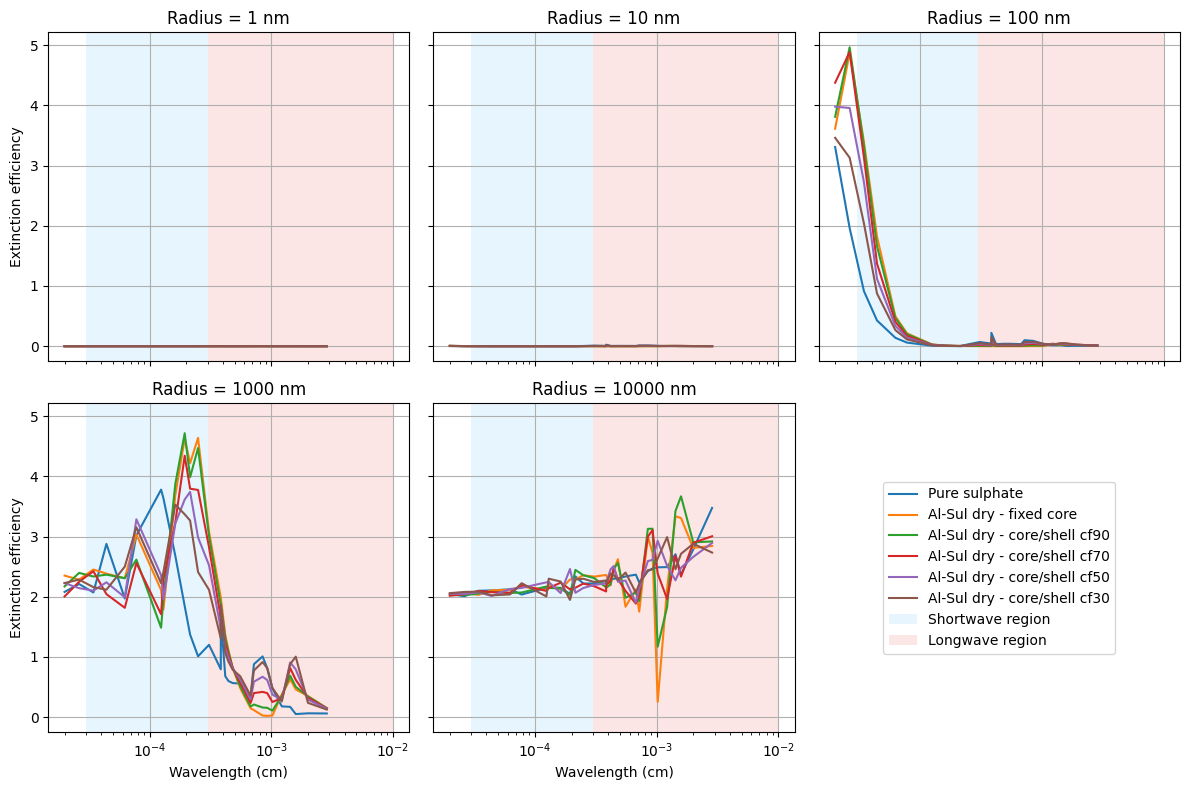

In [7]:
fig, axes = plot_optical_property('qext', ylabel='Extinction efficiency', yscale='linear', save=True)
plt.show()

### Single scattering albedo

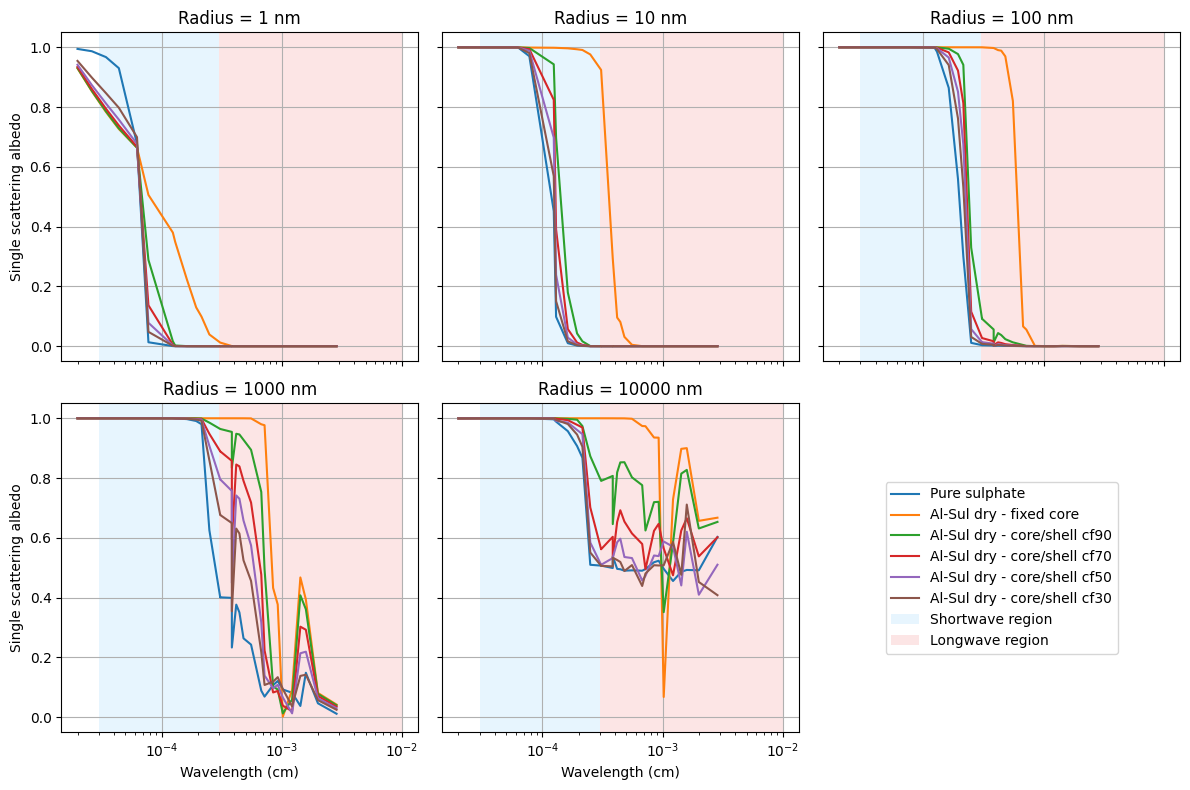

In [8]:
fig, axes = plot_optical_property('ssa', ylabel='Single scattering albedo', yscale='linear', save=True)
plt.show()

### Asymmetry factor

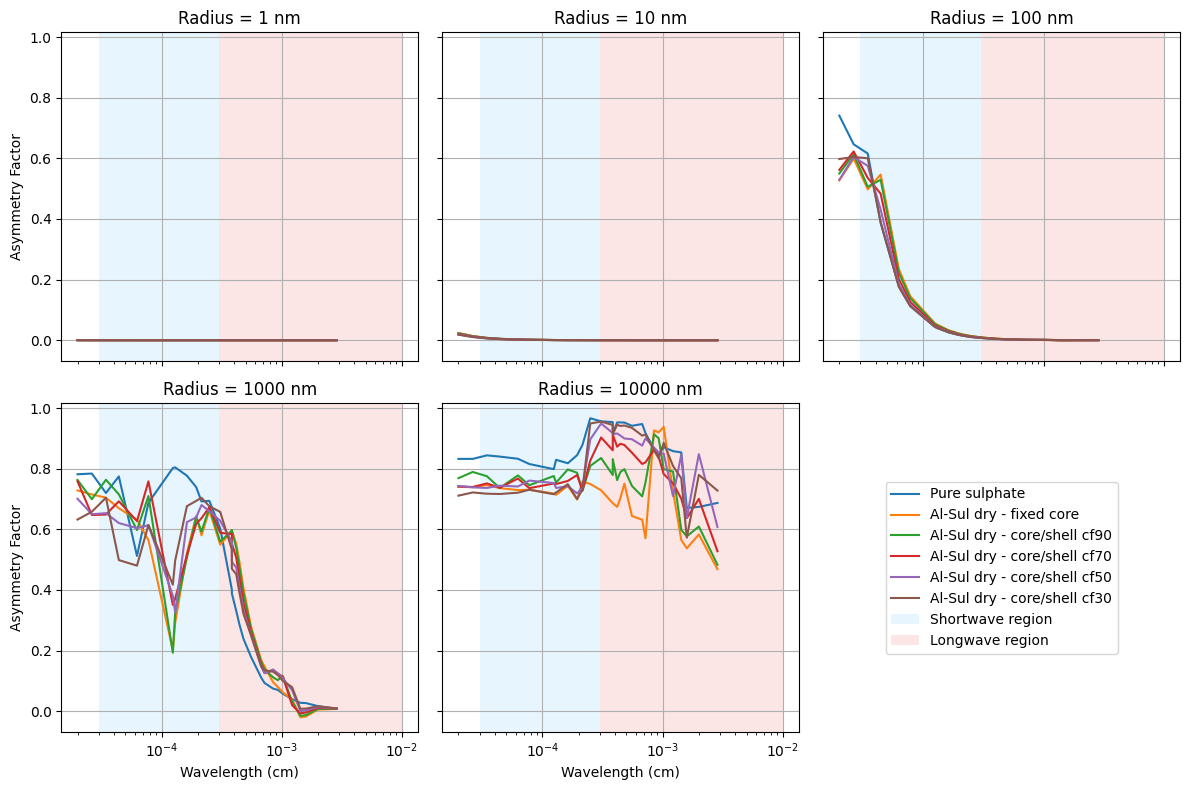

In [41]:
fig, axes = plot_optical_property('asy', ylabel='Asymmetry Factor', yscale='linear', save=True)
plt.show()

### Converting to size parameter
Qext, SSA and Asy are functions of size parameter, x


In [10]:
x = 2*np.pi * ds.ALSUL_fixed_dry_r / ds.wave

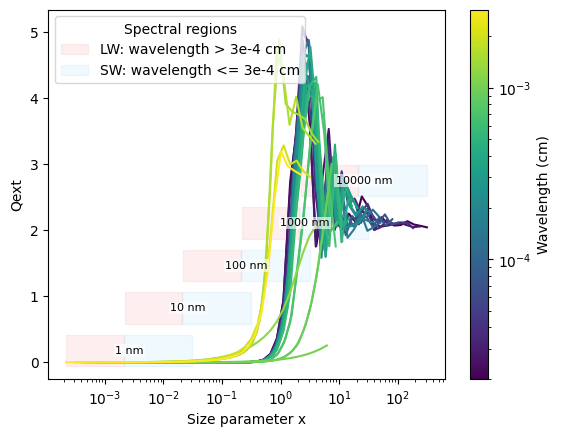

In [31]:
r = ds.ALSUL_fixed_dry_r          # dims: (radius_bin,)  -- use outer radius for core/shell cases
wave = ds.wave                     # dims: (wave,)
qext = ds.ALSUL_fixed_dry_qext     # dims: (radius_bin, wave) -- your Mie output, same shape as x will be
ssa  = ds.ALSUL_fixed_dry_ssa
g    = ds.ALSUL_fixed_dry_asy

norm = mcolors.LogNorm(vmin=float(wave.min()), vmax=float(wave.max()))
cmap = cm.viridis

fig, ax = plt.subplots()
for i in range(wave.sizes['wave']):
    x_i = 2 * np.pi * r / wave.isel(wave=i)          # 1D, over radius_bin, scalar wave
    qext_i = ds.ALSUL_fixed_dry_qext.isel(wave=i)     # 1D, over radius_bin
    ax.plot(x_i, qext_i, color=cmap(norm(float(wave.isel(wave=i)))))

ax.set_xscale('log')
ax.set_xlabel('Size parameter x')
ax.set_ylabel('Qext')
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax, label='Wavelength (cm)')
plt.show()

In [19]:
r_r100 = target_radii[2]
x_r100 = 2 * np.pi * r_r100 / ds.wave
x_r100

<xarray.DataArray 'wave' (wave: 30)> Size: 240B
array([3.14159265, 2.38761042, 1.82212374, 1.42314147, 1.00530965,
       0.80738931, 0.50579642, 0.48380527, 0.3864159 , 0.32358404,
       0.29216812, 0.25132741, 0.20420352, 0.20420352, 0.16336282,
       0.16336282, 0.15016813, 0.14137167, 0.13069025, 0.11309734,
       0.09299114, 0.08733628, 0.07414159, 0.0678584 , 0.06157522,
       0.05152212, 0.0439823 , 0.03958407, 0.03141593, 0.02199115])
Coordinates:
  * wave     (wave) float64 240B 2e-05 2.632e-05 3.448e-05 ... 0.002 0.002857

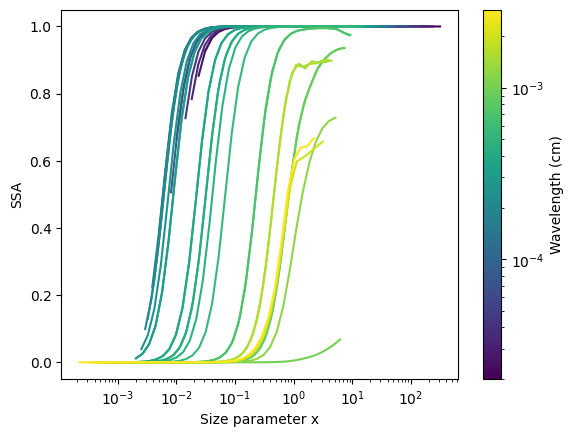

In [36]:
fig, ax = plt.subplots()
for i in range(wave.sizes['wave']):
    x_i = 2 * np.pi * r / wave.isel(wave=i)          # 1D, over radius_bin, scalar wave
    ssa_i = ds.ALSUL_fixed_dry_ssa.isel(wave=i)     # 1D, over radius_bin
    ax.plot(x_i, ssa_i, color=cmap(norm(float(wave.isel(wave=i)))))

ax.set_xscale('log')
ax.set_xlabel('Size parameter x')
ax.set_ylabel('SSA')
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax, label='Wavelength (cm)')
plt.show()

In [39]:
ds

<xarray.Dataset> Size: 445kB
Dimensions:                            (wave: 30, bin: 37)
Coordinates:
  * wave                               (wave) float64 240B 2e-05 ... 0.002857
  * bin                                (bin) float64 296B 1.0 2.0 ... 36.0 37.0
Data variables: (12/201)
    refidx_r                           (wave) float64 240B ...
    refidx_i                           (wave) float64 240B ...
    PRSUL_refidx_r                     (wave) float64 240B ...
    PRSUL_refidx_i                     (wave) float64 240B ...
    PRSUL_r                            (bin) float64 296B 3.43e-08 ... 0.2048
    PRSUL_rmass                        (bin) float64 296B ...
    ...                                 ...
    PRSUL_qabs                         (bin, wave) float64 9kB 2.173e-10 ... ...
    ALSUL_fixed_dry_qabs               (bin, wave) float64 9kB 4.104e-08 ... ...
    ALSUL_coreshell_cf90_dry_qabs      (bin, wave) float64 9kB 3.764e-08 ... ...
    ALSUL_coreshell_cf70_dry_qabs      (bin, wave) float64 9kB 3.045e-08 ... ...
    ALSUL_coreshell_cf50_dry_qabs      (bin, wave) float64 9kB 2.272e-08 ... ...
    ALSUL_coreshell_cf30_dry_qabs      (bin, wave) float64 9kB 1.438e-08 ... ...

### Q scattering and Q absorption

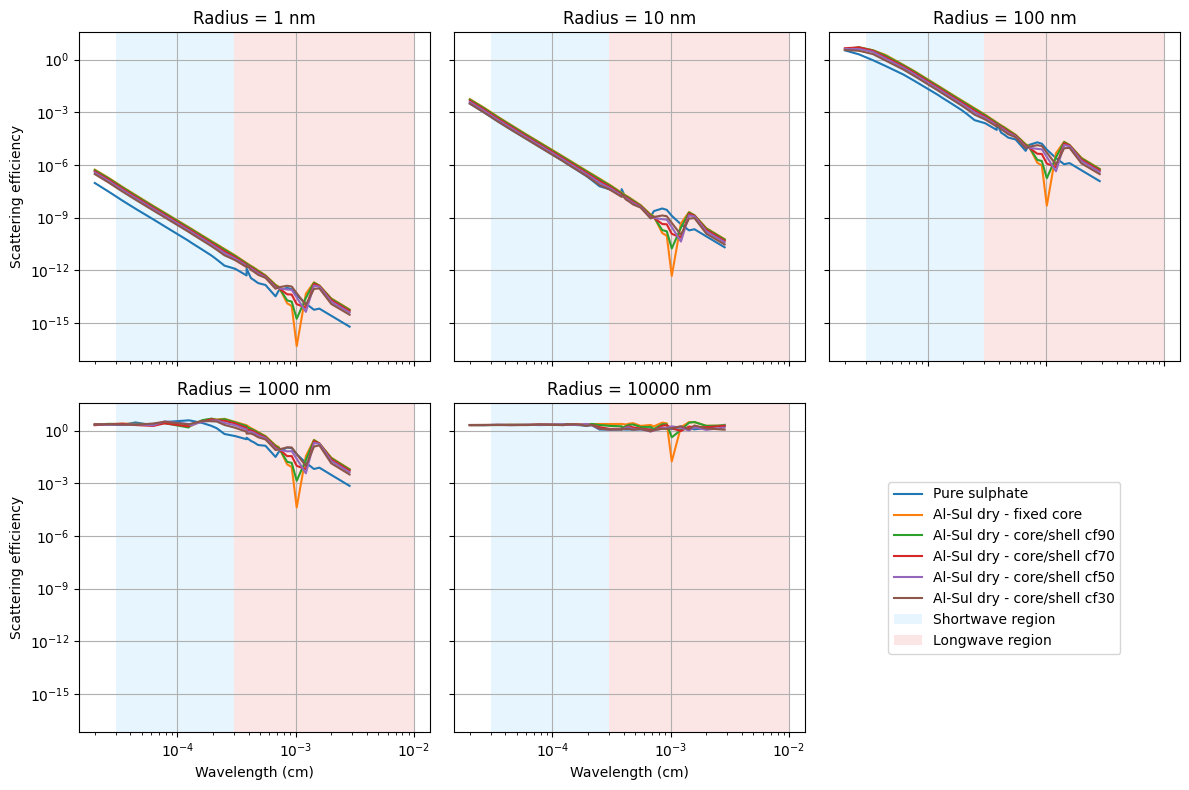

In [42]:
for variable in variable_label.keys():
    ds[f'{variable}_qsca'] = ds[f'{variable}_qext'] * (ds[f'{variable}_ssa'])

fig, axes = plot_optical_property('qsca', ylabel='Scattering efficiency', yscale='log', save=True)
plt.show()

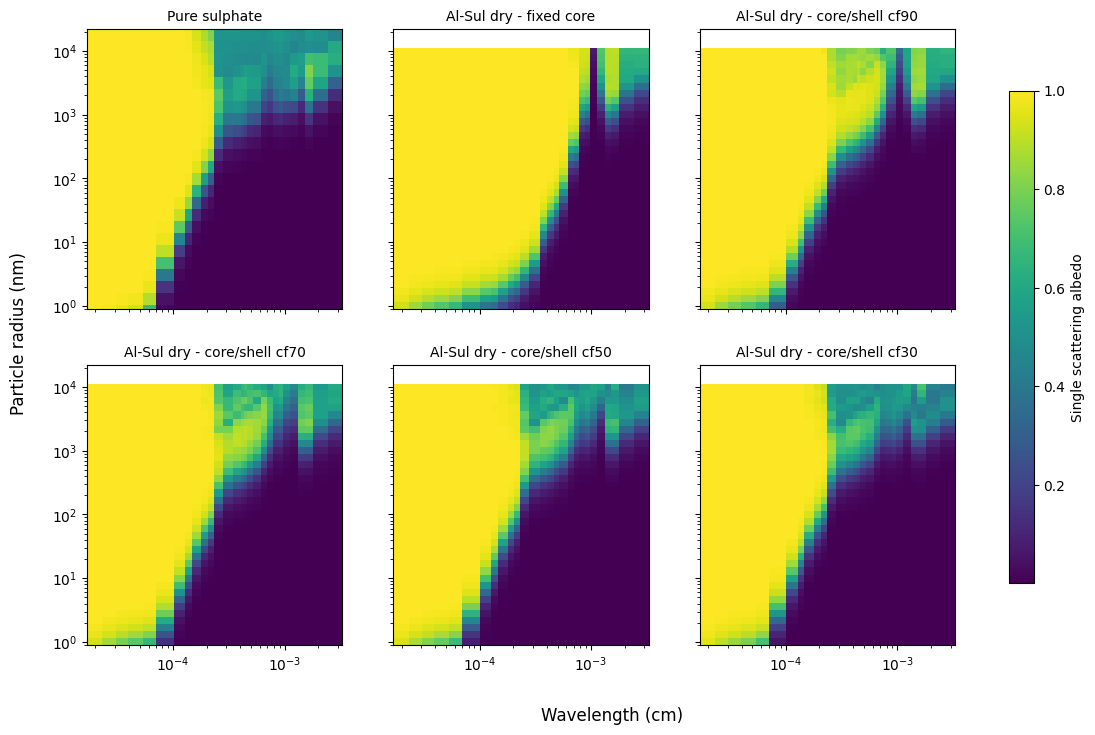

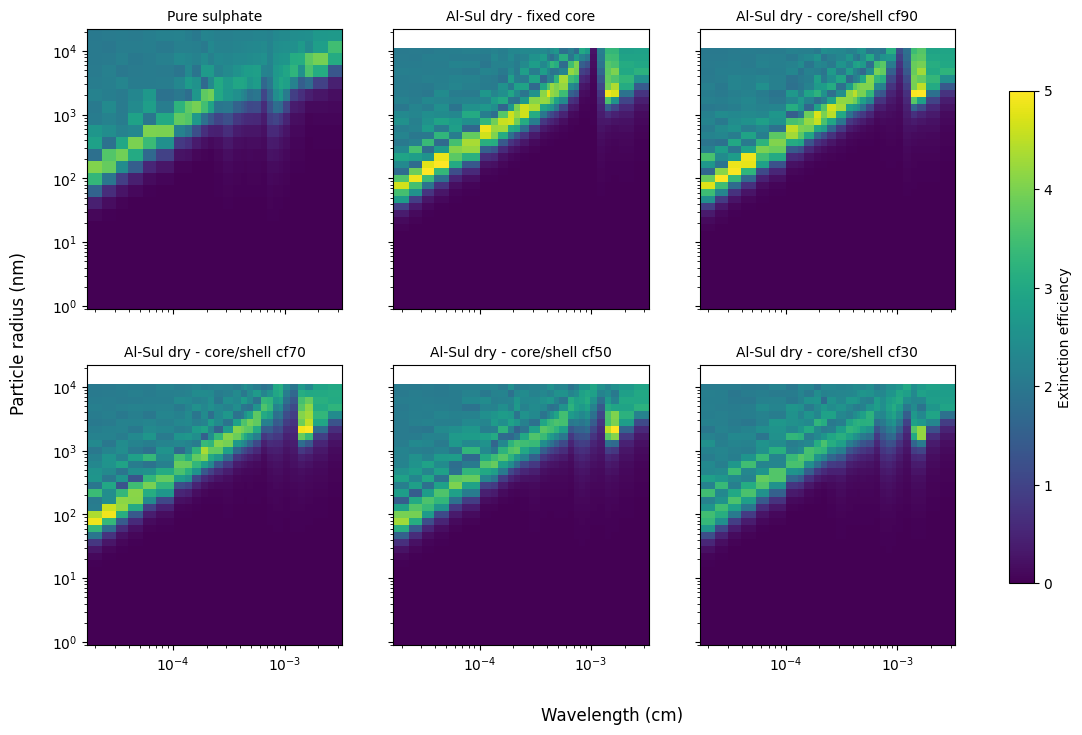

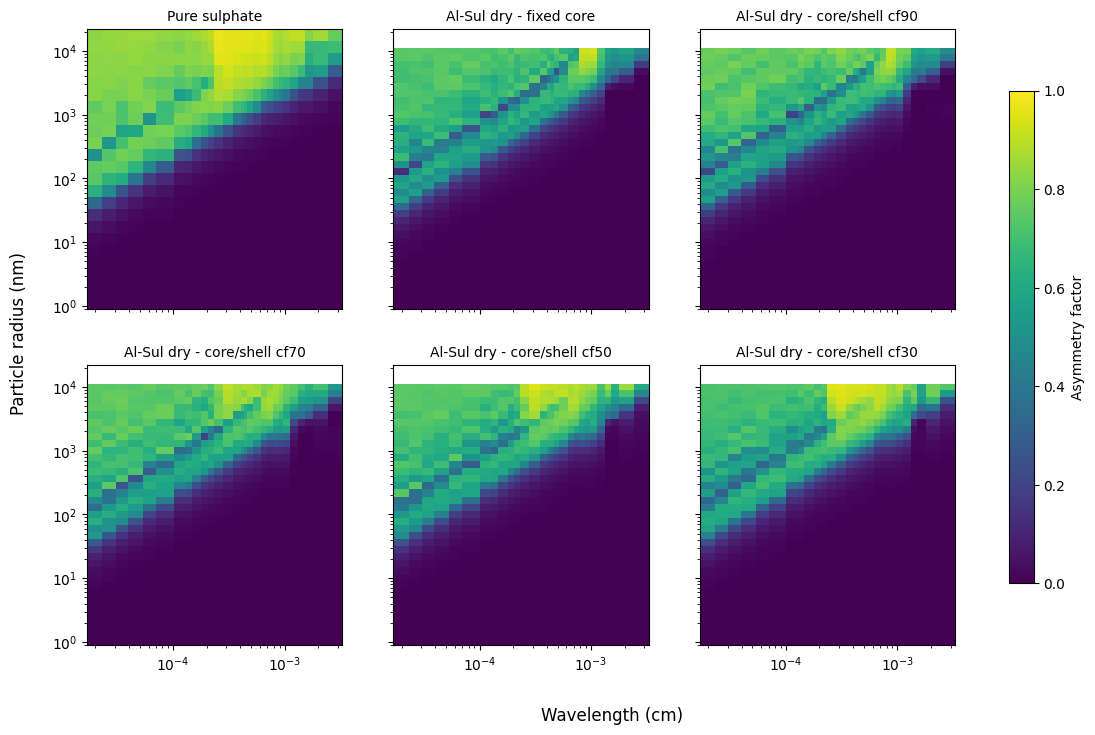

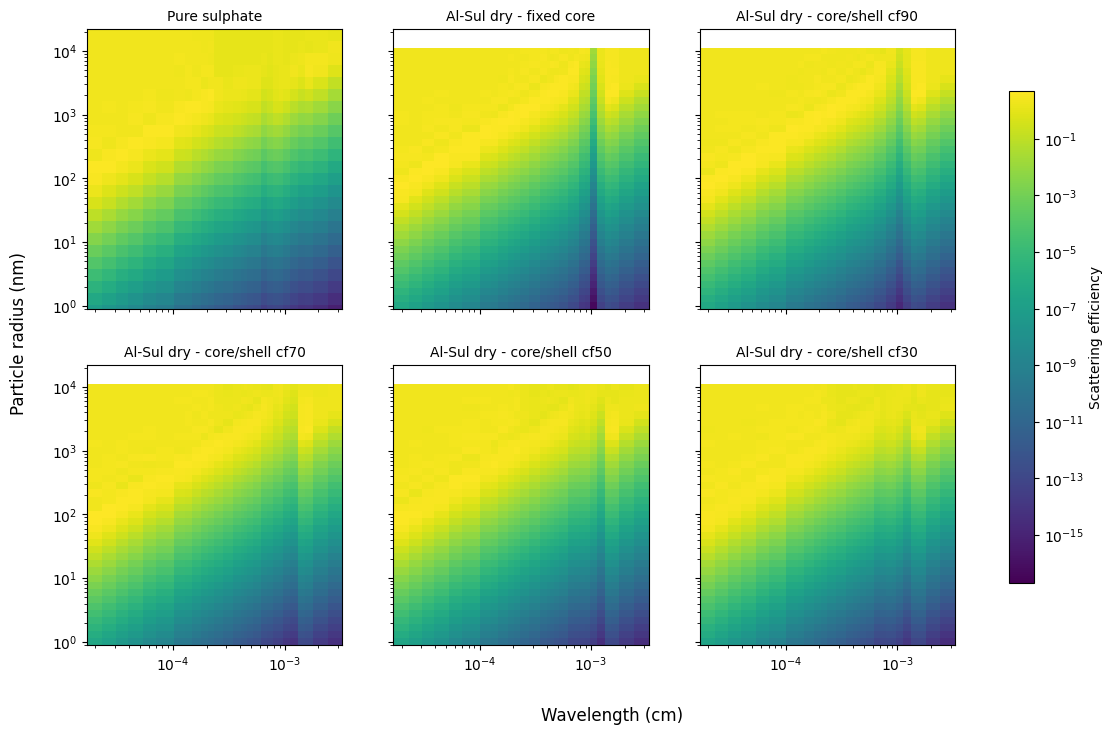

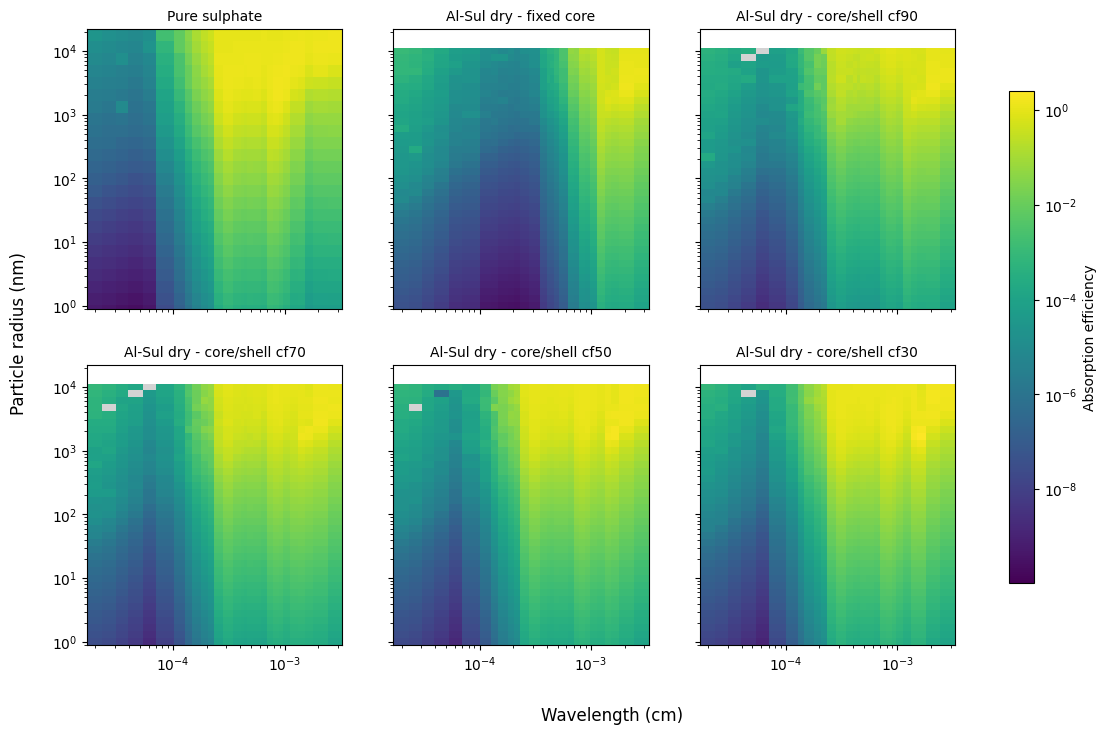

In [56]:
def plot_property_heatmaps(property_name):
    property_config = {
        'ssa': ('Single scattering albedo', 'linear', 1e-6, 1.0),
        'qext': ('Extinction efficiency', 'linear', 0.0, 5.0),
        'asy': ('Asymmetry factor', 'linear', 0.0, 1.0),
        'qsca': ('Scattering efficiency', 'log', None, None),
        'qabs': ('Absorption efficiency', 'log', None, None),
    }
    if property_name not in property_config:
        raise ValueError(f'Unsupported optical property: {property_name}')

    title, scale, vmin, vmax = property_config[property_name]
    wave_values = ds.wave.values
    keep = np.unique(wave_values, return_index=True)[1]
    keep.sort()
    wave_unique = wave_values[keep]

    values_by_variable = {}
    for variable in variable_label:
        qext_values = ds[f'{variable}_qext']
        ssa_values = ds[f'{variable}_ssa']
        if property_name == 'qsca':
            values_by_variable[variable] = (qext_values * ssa_values).values[:, keep]
        elif property_name == 'qabs':
            values_by_variable[variable] = (qext_values * (1 - ssa_values)).values[:, keep]
        else:
            values_by_variable[variable] = ds[f'{variable}_{property_name}'].values[:, keep]

    all_values = np.concatenate([values.ravel() for values in values_by_variable.values()])
    finite_values = all_values[np.isfinite(all_values)]
    if scale == 'log':
        positive_values = finite_values[finite_values > 0]
        if positive_values.size == 0:
            raise ValueError(f'No positive values available to plot for {property_name}.')
        vmin = positive_values.min() if vmin is None else vmin
        vmax = positive_values.max() if vmax is None else vmax
        if vmin >= vmax:
            vmax = np.nextafter(vmin, np.inf)
        norm = mcolors.LogNorm(vmin=vmin, vmax=vmax)
    else:
        norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    cmap = plt.get_cmap('viridis').copy()
    cmap.set_bad('lightgray')
    fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
    for ax, (variable, label) in zip(axes.flat, variable_label.items()):
        radius_nm = ds[f'{variable}_r'].values * 1e7
        values = values_by_variable[variable]
        if scale == 'log':
            values = np.ma.masked_where(~np.isfinite(values) | (values <= 0), values)
        else:
            values = np.ma.masked_invalid(values)

        mesh = ax.pcolormesh(
            wave_unique, radius_nm, values,
            norm=norm, cmap=cmap, shading='auto',
        )
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_title(label, fontsize=10)
        ax.set_ylim(0.9, 2.2e4)

    fig.supxlabel('Wavelength (cm)')
    fig.supylabel('Particle radius (nm)', x=0.07)
    fig.colorbar(mesh, ax=axes, shrink=0.8, label=title)
    # mask_note = ' (gray: missing or nonpositive)' if scale == 'log' else ''
    # fig.suptitle(f'{title} vs radius and wavelength{mask_note}')
    plt.show()
    return fig, axes


for property_name in ('ssa', 'qext', 'asy', 'qsca', 'qabs'):
    plot_property_heatmaps(property_name)

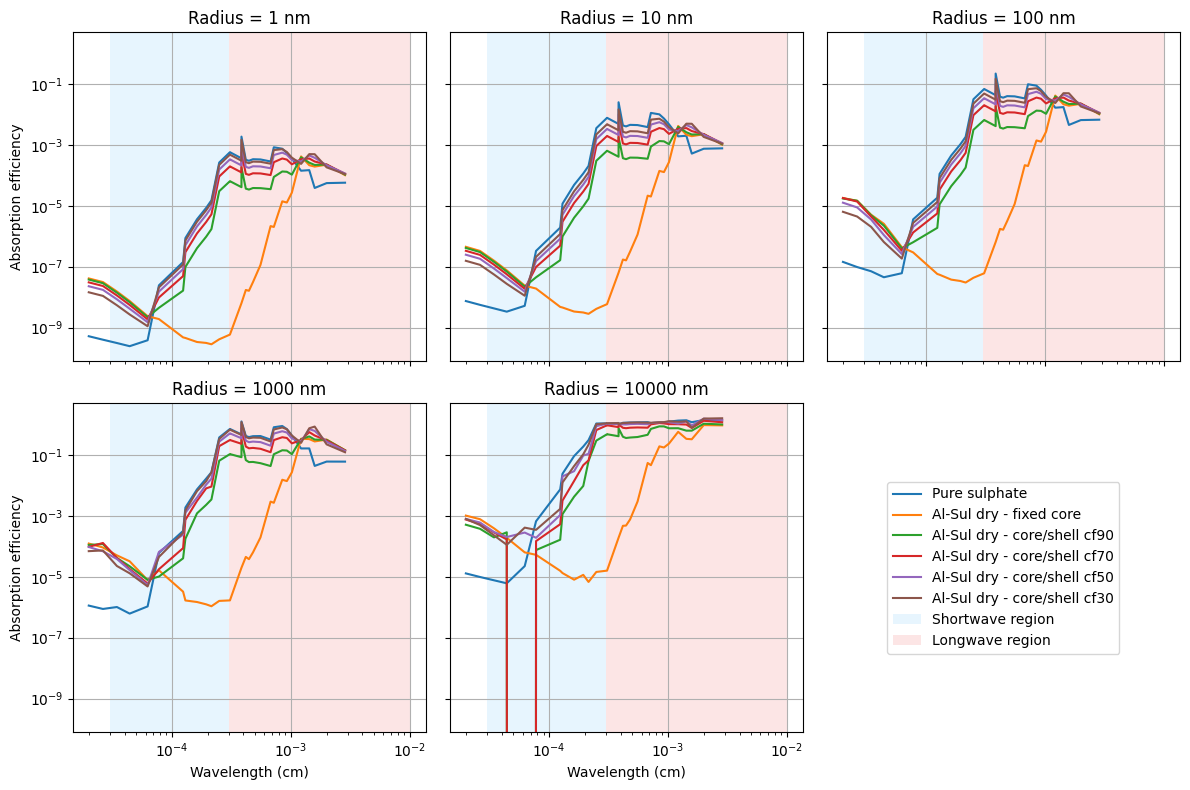

In [ ]:
# Remove repeated wavelengths before plotting the mesh.
wave_values = ds.wave.values
keep = np.unique(wave_values, return_index=True)[1]
keep.sort()
wave_values = wave_values[keep]

SW_LW_BOUNDARY = 3e-4  # cm
run_types = list(variable_label.items())

var_norms = {   # (norm_type, vmin, vmax) per variable
    'ssa':  ('log', 1e-6, 1.0),
    'qext': ('linear', 0.0, 5.0),
    'asy':  ('linear', 0.0, 1.0),
}

for var, (kind, vmin, vmax) in var_norms.items():
    norm = mcolors.LogNorm(vmin, vmax) if kind == 'log' else mcolors.Normalize(vmin, vmax)

    fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
    for ax, (prefix, label) in zip(axes.flat, run_types):
        r_nm = ds[f'{prefix}_r'].values * 1e7            # cm -> nm
        data = ds[f'{prefix}_{var}'].values[:, keep]      # (bin, wave)
        if kind == 'log':
            data = np.clip(data, vmin, vmax)

        mesh = ax.pcolormesh(wave_values, r_nm, data, norm=norm, cmap='viridis', shading='auto')
        ax.set_xscale('log'); ax.set_yscale('log')
        ax.axvline(SW_LW_BOUNDARY, color='k', lw=0.8, ls='--', alpha=0.6)
        ax.set_title(label, fontsize=10)
        ax.set_ylim(0.9, 2.2e4)

    fig.supxlabel('Wavelength (cm)')
    fig.supylabel('Particle radius (nm)')
    fig.colorbar(mesh, ax=axes, shrink=0.8, label=var)
    fig.suptitle(f'{var} vs radius and wavelength (dry runs)')
    plt.show()